Demo to IA Computing, Cambridge Engineering
Flavia Mancini Oct 2025


In [43]:
# import libraries 

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML


In [45]:
# Set parameters
N = 50
box_size = 10
step_scale = 0.1

# Initialize positions and velocities
rng = np.random.default_rng()
pos = rng.uniform(0, box_size, size=(N, 2)) # 👉 pos is a variable storing particle positions.
vel = rng.normal(scale=step_scale, size=(N, 2)) # 👉 vel is a variable storing particle velocities.

# A variable is just a name for a value — like a labelled box.


Text(0.5, 1.0, 'Bouncing Particles Simulation')

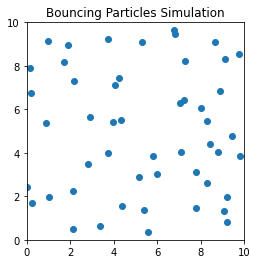

In [46]:
# Create plot
fig, ax = plt.subplots()
scat = ax.scatter(pos[:, 0], pos[:, 1])
ax.set_xlim(0, box_size)
ax.set_ylim(0, box_size)
ax.set_aspect('equal')
ax.set_title("Bouncing Particles Simulation")


In [47]:
# Update function
# A function is a block of code that does a job, and you can reuse it any time — like a washing machine.
def update(frame):
    global pos, vel
    pos += vel

    # Loops let the computer repeat instructions efficiently — like saying ‘bounce for 5 minutes’ instead of writing ‘bounce’ 300 times.
    for i in range(N):
        for dim in [0, 1]:  # x and y

            # Conditionals let your program decide what to do — like ‘if it’s raining, bring an umbrella'
            if pos[i, dim] < 0 or pos[i, dim] > box_size:
                vel[i, dim] *= -1  # Reverse direction
                # Ensure the particle stays inside the box
                pos[i, dim] = max(0, min(pos[i, dim], box_size))

    scat.set_offsets(pos)
    return scat,



In [49]:
# Create animation and store in variable
anim = FuncAnimation(fig, update, frames=200, interval=50)

# Display as HTML animation
HTML(anim.to_jshtml())

🧪 Example Unit Test

To make the code testable, we can first extract the position/velocity update logic into a separate pure function, e.g.:


In [50]:
def update_positions(pos, vel, box_size):
    pos = pos + vel.copy()
    for i in range(pos.shape[0]):
        for dim in range(2):
            if pos[i, dim] < 0 or pos[i, dim] > box_size:
                vel[i, dim] *= -1
                pos[i, dim] = max(0, min(pos[i, dim], box_size))
    return pos, vel

Then we can write a basic unit test to check if bouncing works at the boundary:

In [52]:
def test_particle_bounce_off_wall():
    # Particle just outside box bounds
    pos = np.array([[11.0, 5.0]])  # x is out of bounds (> box_size)
    vel = np.array([[1.0, 0.0]])   # moving in +x direction
    box_size = 10

    updated_pos, updated_vel = update_positions(pos.copy(), vel.copy(), box_size)

    assert updated_pos[0, 0] <= box_size, "Particle should be inside the box"
    assert updated_vel[0, 0] == -1.0, "Velocity should have reversed in x"
    print("✅ test_particle_bounce_off_wall passed")

In [53]:
test_particle_bounce_off_wall()

✅ test_particle_bounce_off_wall passed





🛠️ You don’t have to love computing (yet), but you can learn it step-by-step.

📐 Like engineering drawing or lab work, this is a tool — and you’re here to master it.

❌ Mistakes are expected.

✅ Curiosity is enough.